# Which customers leave, and how well can a model spot them in time?

**Research question.** For a telecom company, which customer characteristics are most strongly linked to leaving (churn), when in the customer relationship is the risk highest, and how much better than chance can a simple, explainable model target customers for retention offers?

**Data.** [IBM Telco Customer Churn](https://github.com/IBM/telco-customer-churn-on-icp4d), also widely used on Kaggle. 7,043 customers of a fictional California telecom provider, with services, contract, billing, tenure and whether they left in the last month. IBM created it as a **sample dataset**, so it is realistic but not real company data.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
BG, FG, MUTED, A1, A2, A3, A4 = '#0F0E17', '#F4F1EA', '#9A93A8', '#E8577C', '#E8B86D', '#6D5EF5', '#38BDF8'
plt.rcParams.update({'figure.facecolor':BG,'axes.facecolor':BG,'axes.edgecolor':'#3a3747','axes.labelcolor':MUTED,
  'xtick.color':MUTED,'ytick.color':MUTED,'text.color':FG,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,
  'axes.grid':True,'axes.axisbelow':True,'grid.color':'#24222f','savefig.facecolor':BG,'savefig.dpi':160,'legend.frameon':False})
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from sklearn.calibration import calibration_curve

In [2]:
df = pd.read_csv('Telco-Customer-Churn.csv')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')
print('Blank TotalCharges:', df['TotalCharges'].isna().sum(), '| their tenure:', df.loc[df.TotalCharges.isna(),'tenure'].unique())
df['TotalCharges'] = df['TotalCharges'].fillna(0)   # brand-new customers (tenure 0) have not been billed yet
df['churn'] = (df['Churn']=='Yes').astype(int)
print(df.shape, '| churn rate:', round(df.churn.mean(),3))

Blank TotalCharges: 11 | their tenure: [0]
(7043, 22) | churn rate: 0.265


## 1. Who leaves?

In [3]:
def rate(col):
    t = df.groupby(col)['churn'].agg(['mean','size']).rename(columns={'mean':'churn_rate','size':'customers'})
    return t.sort_values('churn_rate', ascending=False)
for col in ['Contract','InternetService','PaymentMethod','TechSupport','SeniorCitizen','PaperlessBilling']:
    print(rate(col).round(3), '\n')

                churn_rate  customers
Contract                             
Month-to-month       0.427       3875
One year             0.113       1473
Two year             0.028       1695 

                 churn_rate  customers
InternetService                       
Fiber optic           0.419       3096
DSL                   0.190       2421
No                    0.074       1526 

                           churn_rate  customers
PaymentMethod                                   
Electronic check                0.453       2365
Mailed check                    0.191       1612
Bank transfer (automatic)       0.167       1544
Credit card (automatic)         0.152       1522 

                     churn_rate  customers
TechSupport                               
No                        0.416       3473
Yes                       0.152       2044
No internet service       0.074       1526 

               churn_rate  customers
SeniorCitizen                       
1                   0.41

In [4]:
bands = [0,6,12,24,48,72]
df['tenure_band'] = pd.cut(df['tenure'], bands, include_lowest=True, labels=['0-6 months','7-12','13-24','25-48','49-72'])
tb = df.groupby(['tenure_band','Contract'], observed=True)['churn'].mean().unstack()
print(tb.round(3))
print(rate('tenure_band').sort_index().round(3))

Contract     Month-to-month  One year  Two year
tenure_band                                    
0-6 months            0.552     0.103     0.000
7-12                  0.420     0.106     0.000
13-24                 0.377     0.081     0.000
25-48                 0.329     0.106     0.022
49-72                 0.260     0.129     0.033
             churn_rate  customers
tenure_band                       
0-6 months        0.529       1481
7-12              0.359        705
13-24             0.287       1024
25-48             0.204       1594
49-72             0.095       2239


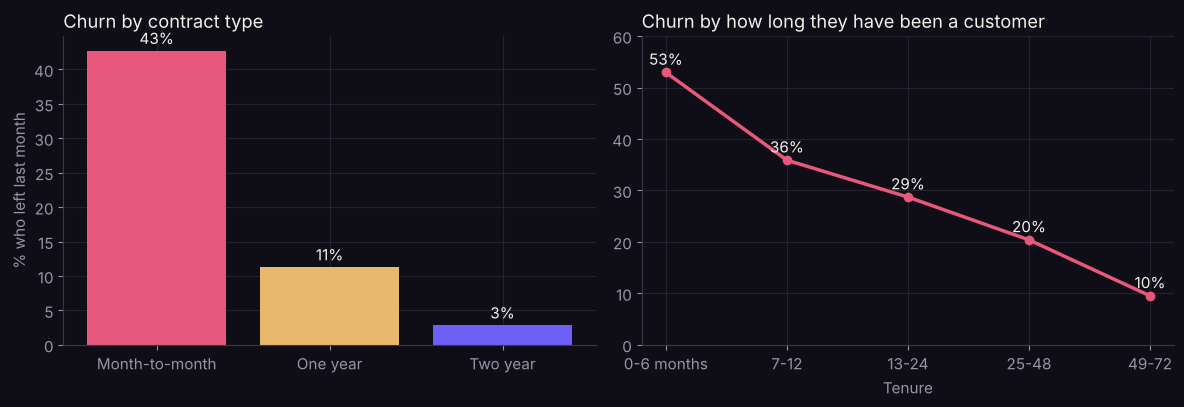

In [5]:
fig, axes = plt.subplots(1,2, figsize=(12,4.2))
r = rate('Contract').reindex(['Month-to-month','One year','Two year'])
axes[0].bar(r.index, r['churn_rate']*100, color=[A1,A2,A3])
for i,v in enumerate(r['churn_rate']*100): axes[0].text(i, v+1, f'{v:.0f}%', ha='center', color=FG)
axes[0].set_ylabel('% who left last month'); axes[0].set_title('Churn by contract type', loc='left', color=FG)
t = rate('tenure_band').sort_index()
axes[1].plot(t.index.astype(str), t['churn_rate']*100, marker='o', color=A1, lw=2.5)
for x,v in zip(t.index.astype(str), t['churn_rate']*100): axes[1].text(x, v+1.5, f'{v:.0f}%', ha='center', color=FG)
axes[1].set_ylim(0, 60); axes[1].set_xlabel('Tenure'); axes[1].set_title('Churn by how long they have been a customer', loc='left', color=FG)
fig.tight_layout(); fig.savefig('figures/01_churn_by_contract_tenure.png'); plt.show()

## 2. Models

A hold-out test set (25%, stratified) is kept aside and only used once at the end. Model choice uses 5-fold cross-validation on the training set.

In [6]:
cat = ['gender','SeniorCitizen','Partner','Dependents','PhoneService','MultipleLines','InternetService','OnlineSecurity','OnlineBackup',
       'DeviceProtection','TechSupport','StreamingTV','StreamingMovies','Contract','PaperlessBilling','PaymentMethod']
num = ['tenure','MonthlyCharges','TotalCharges']
X = df[cat+num].copy(); X['SeniorCitizen'] = X['SeniorCitizen'].astype(str); y = df['churn']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
pre = ColumnTransformer([('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), cat), ('num', StandardScaler(), num)])
logit = Pipeline([('pre', pre), ('m', LogisticRegression(max_iter=2000, C=1.0))])
gbm = Pipeline([('pre', ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat), ('num','passthrough', num)])),
                ('m', HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, random_state=42))])
cv = StratifiedKFold(5, shuffle=True, random_state=42)
for name, model in [('Logistic regression', logit), ('Gradient boosting', gbm)]:
    s = cross_val_score(model, X_tr, y_tr, cv=cv, scoring='roc_auc')
    print(f'{name}: cross-validated ROC-AUC {s.mean():.3f} (+/- {s.std():.3f})')

Logistic regression: cross-validated ROC-AUC 0.844 (+/- 0.015)


Gradient boosting: cross-validated ROC-AUC 0.838 (+/- 0.011)


In [7]:
logit.fit(X_tr, y_tr); gbm.fit(X_tr, y_tr)
res = {}
for name, model in [('Logistic regression', logit), ('Gradient boosting', gbm)]:
    p = model.predict_proba(X_te)[:,1]; res[name] = p
    print(f'{name} on held-out test: ROC-AUC {roc_auc_score(y_te,p):.3f}, PR-AUC {average_precision_score(y_te,p):.3f} (baseline {y_te.mean():.3f})')

Logistic regression on held-out test: ROC-AUC 0.847, PR-AUC 0.639 (baseline 0.265)
Gradient boosting on held-out test: ROC-AUC 0.836, PR-AUC 0.646 (baseline 0.265)


## 3. Is it useful? Targeting the riskiest customers

In [8]:
p = res['Logistic regression']
order = np.argsort(-p); ys = y_te.values[order]
captured = np.cumsum(ys)/ys.sum(); share = np.arange(1, len(ys)+1)/len(ys)
for k in [0.1, 0.2, 0.3]:
    i = int(k*len(ys))-1
    print(f'Contacting the riskiest {k:.0%} of customers reaches {captured[i]:.0%} of those who leave ({captured[i]/k:.1f}x random)')
frac_pos, mean_pred = calibration_curve(y_te, p, n_bins=10, strategy='quantile')
print('Calibration (predicted vs actual churn by decile):'); print(pd.DataFrame({'predicted':mean_pred.round(2),'actual':frac_pos.round(2)}).to_string(index=False))

Contacting the riskiest 10% of customers reaches 28% of those who leave (2.8x random)
Contacting the riskiest 20% of customers reaches 50% of those who leave (2.5x random)
Contacting the riskiest 30% of customers reaches 66% of those who leave (2.2x random)
Calibration (predicted vs actual churn by decile):
 predicted  actual
      0.01    0.01
      0.02    0.02
      0.04    0.03
      0.08    0.12
      0.15    0.15
      0.23    0.22
      0.34    0.35
      0.47    0.42
      0.59    0.60
      0.73    0.74


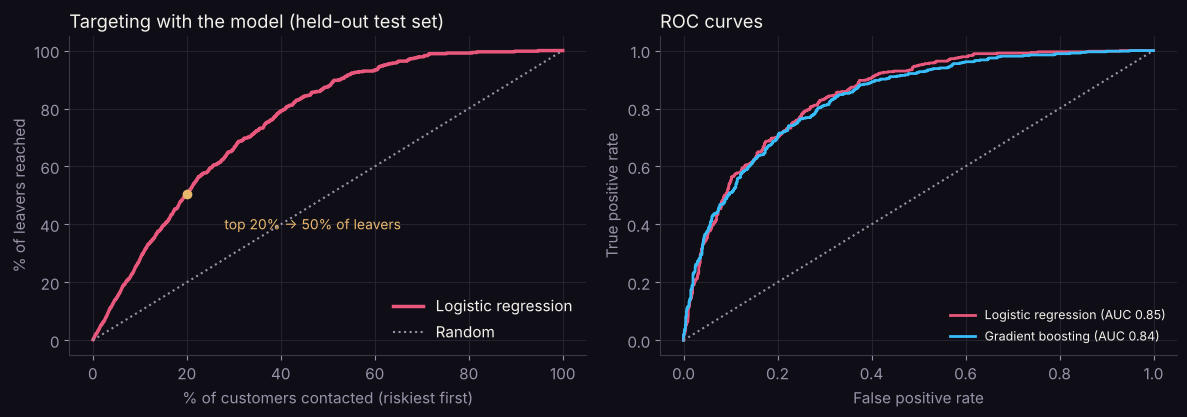

In [9]:
fig, axes = plt.subplots(1,2, figsize=(12,4.3))
axes[0].plot(share*100, captured*100, color=A1, lw=2.5, label='Logistic regression')
axes[0].plot([0,100],[0,100], color=MUTED, ls=':', label='Random')
i20 = int(0.2*len(ys))-1; axes[0].scatter([20],[captured[i20]*100], color=A2, zorder=3)
axes[0].annotate(f'top 20% -> {captured[i20]:.0%} of leavers', (20, captured[i20]*100), xytext=(28, captured[i20]*100-12), color=A2, fontsize=10)
axes[0].set_xlabel('% of customers contacted (riskiest first)'); axes[0].set_ylabel('% of leavers reached'); axes[0].legend(loc='lower right')
axes[0].set_title('Targeting with the model (held-out test set)', loc='left', color=FG)
for name, c in [('Logistic regression', A1), ('Gradient boosting', A4)]:
    fpr, tpr, _ = roc_curve(y_te, res[name]); axes[1].plot(fpr, tpr, color=c, lw=2, label=f'{name} (AUC {roc_auc_score(y_te,res[name]):.2f})')
axes[1].plot([0,1],[0,1], color=MUTED, ls=':'); axes[1].set_xlabel('False positive rate'); axes[1].set_ylabel('True positive rate')
axes[1].legend(loc='lower right', fontsize=9); axes[1].set_title('ROC curves', loc='left', color=FG)
fig.tight_layout(); fig.savefig('figures/02_targeting_and_roc.png'); plt.show()

## 4. What drives the risk? (logistic regression, odds ratios)

num__tenure                             0.28
cat__Contract_Two year                  0.46
cat__InternetService_DSL                0.51
num__MonthlyCharges                     0.57
cat__TechSupport_No internet service    0.71
cat__StreamingTV_No internet service    0.71
cat__StreamingMovies_Yes                1.17
cat__SeniorCitizen_1                    1.20
cat__PaperlessBilling_Yes               1.50
cat__Contract_Month-to-month            1.67
cat__InternetService_Fiber optic        1.75
num__TotalCharges                       1.78
dtype: float64


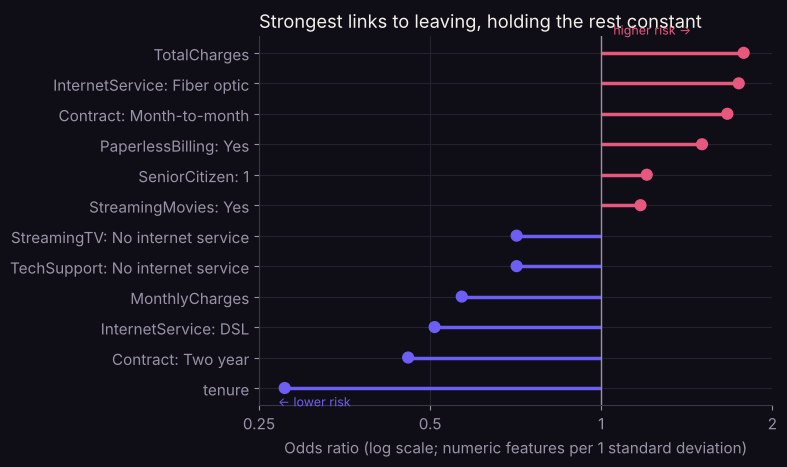

In [10]:
names = logit.named_steps['pre'].get_feature_names_out()
coefs = pd.Series(logit.named_steps['m'].coef_[0], index=names)
orr = np.exp(coefs).sort_values()
show = pd.concat([orr.head(6), orr.tail(6)])
print(show.round(2))
fig, ax = plt.subplots(figsize=(8,4.8))
lab = [n.replace('cat__','').replace('num__','').replace('_',': ') for n in show.index]
ypos = np.arange(len(show)); cols = [A3 if v<1 else A1 for v in show.values]
ax.hlines(ypos, 1, show.values, color=cols, lw=2.5); ax.scatter(show.values, ypos, color=cols, s=60, zorder=3)
ax.set_yticks(ypos, lab); ax.axvline(1, color=MUTED, lw=1)
ax.set_xscale('log'); ax.set_xticks([0.25,0.5,1,2], ['0.25','0.5','1','2']); ax.minorticks_off()
ax.set_xlabel('Odds ratio (log scale; numeric features per 1 standard deviation)')
ax.text(0.27, -0.6, '← lower risk', color=A3, fontsize=9); ax.text(1.05, len(show)-0.4, 'higher risk →', color=A1, fontsize=9)
ax.set_title('Strongest links to leaving, holding the rest constant', loc='left', color=FG)
fig.tight_layout(); fig.savefig('figures/03_odds_ratios.png'); plt.show()

## Limitations

- **Sample data** created by IBM, so patterns may be cleaner than in real customer data.
- **One month of churn**, observed once. It shows who left, not when or why.
- **Association, not cause.** A month-to-month contract is linked to leaving, but moving customers onto longer contracts won't necessarily keep them.
- **Correlated features.** Tenure, total charges and contract overlap, so individual odds ratios should be read together.